# Wstępna EDA — artykuły zebrane ze stron (`data/raw_private`)

**Cel projektu:** zbadać, w jakim stopniu polskie serwisy informacyjne korzystają z AI do (współ)pisania artykułów.

**Zakres tej EDA:** dane ze stron (`data/raw_private/<rok>/<domena>.jsonl`).

**Status zbioru na ten moment (wersja wstępna):**
- 26 domen zdefiniowanych w `data/frame/domains.csv` (kolumny: `domain`, `stratum`, `rank_tranco`),
- cel: do 10 artykułów na domenę na rok,


In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../../data/raw_private")
FRAME_DIR = Path("../../data/frame")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Wczytanie danych

Skanujemy wyłącznie foldery lat (`^\d{4}$`), ignorując inne nie-roczne foldery (np. cache Common Crawl).

In [2]:
YEAR_DIR_RE = re.compile(r"^\d{4}$")

year_dirs = sorted(
    p for p in DATA_DIR.iterdir() if p.is_dir() and YEAR_DIR_RE.match(p.name)
)
print("Znalezione foldery lat:", [p.name for p in year_dirs])

Znalezione foldery lat: ['2020', '2021', '2022', '2023', '2024', '2025']


In [3]:
def load_articles(year_dirs: list[Path]) -> pd.DataFrame:
    rows = []
    for year_dir in year_dirs:
        for jsonl_path in sorted(year_dir.glob("*.jsonl")):
            with jsonl_path.open(encoding="utf-8") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    rec = json.loads(line)
                    rec["collection_year_dir"] = year_dir.name
                    rows.append(rec)
    return pd.DataFrame(rows)


articles = load_articles(year_dirs)
print(f"Wczytano {len(articles)} artykułów z {articles['domain'].nunique()} domen.")
articles.head(3)

Wczytano 1141 artykułów z 23 domen.


,article_id,domain,stratum,url,crawl_id,warc_filename,warc_offset,warc_length,pub_date,pub_year,title,crawl_timestamp,author_present,n_words,languages,text_sha1,text,collection_year_dir
0,e804fd82c414f4da5db268c9611173fb9b8cf13c,demagog.org.pl,S2,https://demagog.org.pl/fake_news/nie-singapur-...,CC-MAIN-2021-04,crawl-data/CC-MAIN-2021-04/segments/1610703529...,284248942,20475,2020-12-15,2020,"Nie, Singapur nie wstrzymał wszystkich szczepień",20210122091715,False,1027,pol,5b6d8e974b5bb302eb284db804f287571feaceb2,"Czas czytania: około\nNie, Singapur nie wstrzy...",2020
1,bad5cb18fbfb05bee88be99346297a83fba97bff,demagog.org.pl,S2,https://demagog.org.pl/wypowiedzi/w-jakich-pan...,CC-MAIN-2021-04,crawl-data/CC-MAIN-2021-04/segments/1610704800...,290712595,20519,2020-07-14,2020,W jakich państwach europejskich szczepi się no...,20210126144952,False,970,pol,9c7b090b2673ffa1aeb1bf050d69572224183d8a,Czas czytania: około\nW jakich państwach europ...,2020
2,92b18235b2f7187d6753bffe2cee1330c8112aef,demagog.org.pl,S2,https://demagog.org.pl/fake_news/nie-to-zdjeci...,CC-MAIN-2021-04,crawl-data/CC-MAIN-2021-04/segments/1610703521...,302420357,18003,2020-05-18,2020,"Nie, to zdjęcie nie pochodzi z tegorocznych ob...",20210120190036,False,388,pol,1fc454ec6f0852d402779272d99fb2684514888e,"Czas czytania: około\nNie, to zdjęcie nie poch...",2020


In [24]:
def load_done_stats(year_dirs: list[Path]) -> pd.DataFrame:
    rows = []
    for year_dir in year_dirs:
        for done_path in sorted(year_dir.glob("*.done")):
            domain = done_path.name[: -len(".done")]
            stats = json.loads(done_path.read_text(encoding="utf-8"))
            stats["domain"] = domain
            stats["collection_year_dir"] = year_dir.name
            rows.append(stats)
    return pd.DataFrame(rows)


done_stats = load_done_stats(year_dirs)
done_stats.head(3)

,kept,tried,candidates,finished_at,domain,collection_year_dir
0,10,17,349,2026-10-19T22:58:23+00:00,demagog.org.pl,2020
1,10,19,600,2026-10-19T22:56:00+00:00,dziennik-polityczny.com,2020
2,10,38,600,2026-10-19T22:54:32+00:00,dziennik.pl,2020


## 2. Pokrycie danych (coverage)

Ile artykułów faktycznie mamy na domenę/rok względem celu (10/domenę/rok), i dla jakich domen zbieranie
jeszcze nie przyniosło żadnych artykułów.

In [5]:
domains_frame = pd.read_csv(FRAME_DIR / "domains.csv")
domains_frame.head(3)

,domain,stratum,rank_tranco
0,onet.pl,S1,977.0
1,wp.pl,S1,807.0
2,interia.pl,S1,1181.0


In [6]:
coverage = (
    articles.groupby(["collection_year_dir", "domain"])
    .size()
    .rename("n_articles")
    .reset_index()
)

coverage_pivot = (
    coverage.pivot(index="domain", columns="collection_year_dir", values="n_articles")
    .fillna(0)
    .astype(int)
)
coverage_pivot = coverage_pivot.reindex(domains_frame["domain"]).fillna(0).astype(int)
coverage_pivot["total"] = coverage_pivot.sum(axis=1)
coverage_pivot = coverage_pivot.merge(
    domains_frame.set_index("domain")[["stratum"]],
    left_index=True,
    right_index=True,
    how="left",
)
coverage_pivot.sort_values("total")

,2020,2021,2022,2023,2024,2025,total,stratum
domain,,,,,,,,
tvmalbork.pl,0,0,0,0,0,0,0,S2
wolnemedia.net,0,0,0,0,0,0,0,S3
rzeczpospolita.pl,0,0,0,0,0,0,0,S2
wpolsce24.tv,0,0,0,0,10,10,20,S3
odkrywamyzakryte.com,10,10,0,0,0,0,20,S3
neon24.pl,0,0,7,10,0,10,27,S3
parezja.pl,10,10,4,4,1,1,30,S3
gazeta.pl,10,10,10,1,1,3,35,S1
globalna.info,10,10,0,10,10,0,40,S3


In [7]:
zero_domains = coverage_pivot[coverage_pivot["total"] == 0]
print(
    f"Domeny bez żadnego zebranego artykułu (jak dotąd): {len(zero_domains)} / {len(coverage_pivot)}"
)
zero_domains

Domeny bez żadnego zebranego artykułu (jak dotąd): 3 / 26


,2020,2021,2022,2023,2024,2025,total,stratum
domain,,,,,,,,
rzeczpospolita.pl,0,0,0,0,0,0,0,S2
wolnemedia.net,0,0,0,0,0,0,0,S3
tvmalbork.pl,0,0,0,0,0,0,0,S2


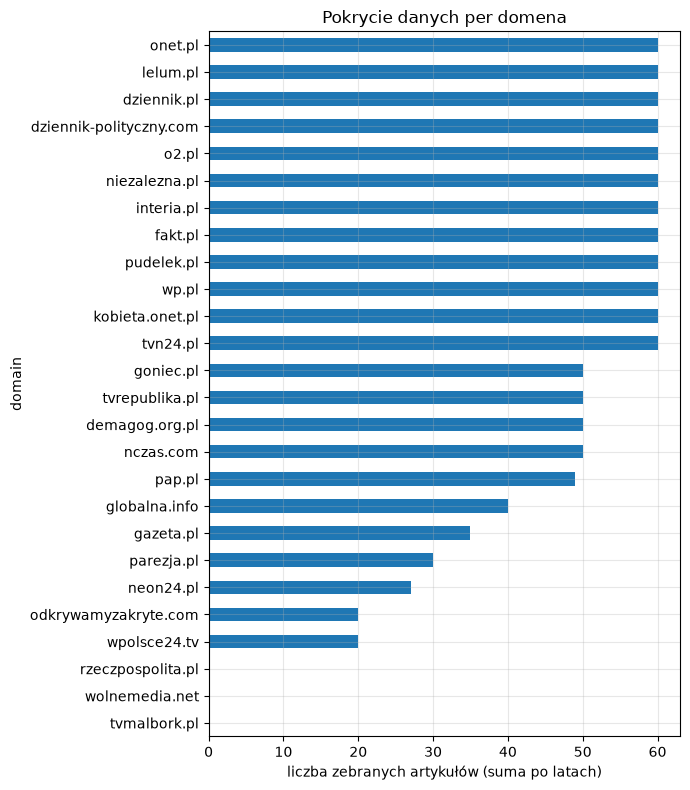

In [8]:
ax = coverage_pivot.sort_values("total")["total"].plot(kind="barh", figsize=(7, 8))
ax.set_xlabel("liczba zebranych artykułów (suma po latach)")
ax.set_title("Pokrycie danych per domena")
plt.tight_layout()
plt.show()

## 3. Lejek zbierania (`candidates -> tried -> kept`)

Pliki `.done` mówią, ile kandydatów URL rozważono, ile faktycznie spróbowano sparsować i ile przeszło nasze
kryteria jakości. Niski `kept/tried` dla danej domeny sugeruje, że np. parser nie radzi sobie z jej layoutem,
albo artykuły nie spełniają naszych założeń (np. zbyt krótkie, zła detekcja języka) — to ważny sygnał do
poprawy scrapera, nie tylko ciekawostka EDA.

In [ ]:
done_stats["kept_ratio"] = done_stats["kept"] / done_stats["tried"].replace(0, pd.NA)

funnel = (
    done_stats.groupby("domain")[["candidates", "tried", "kept"]]
    .sum()
    .merge(
        domains_frame.set_index("domain")[["stratum"]],
        left_index=True,
        right_index=True,
        how="left",
    )
)
funnel["kept_ratio"] = funnel["kept"] / funnel["tried"].replace(0, pd.NA)
funnel.sort_values("kept")

,candidates,tried,kept,stratum,kept_ratio
domain,,,,,
wolnemedia.net,0,0,0,S3,<NA>
tvmalbork.pl,3001,3001,0,S2,0.0
rzeczpospolita.pl,0,0,0,S2,<NA>
wpolsce24.tv,856,36,20,S3,0.555556
odkrywamyzakryte.com,1688,554,20,S3,0.036101
neon24.pl,961,572,27,S3,0.047203
parezja.pl,3281,2857,30,S3,0.010501
gazeta.pl,3600,2091,35,S1,0.016738
globalna.info,2270,402,40,S3,0.099502


In [10]:
failed_scraping = funnel[(funnel["candidates"] > 0) & (funnel["kept"] == 0)]
no_candidates = funnel[funnel["candidates"] == 0]
print(
    f"Domeny z kandydatami, ale 0 'kept' (problem z parsowaniem/jakością): {len(failed_scraping)}"
)
print(list(failed_scraping.index))
print(f"Domeny bez żadnych kandydatów w indeksie Common Crawl: {len(no_candidates)}")
print(list(no_candidates.index))

Domeny z kandydatami, ale 0 'kept' (problem z parsowaniem/jakością): 1
['tvmalbork.pl']
Domeny bez żadnych kandydatów w indeksie Common Crawl: 2
['rzeczpospolita.pl', 'wolnemedia.net']


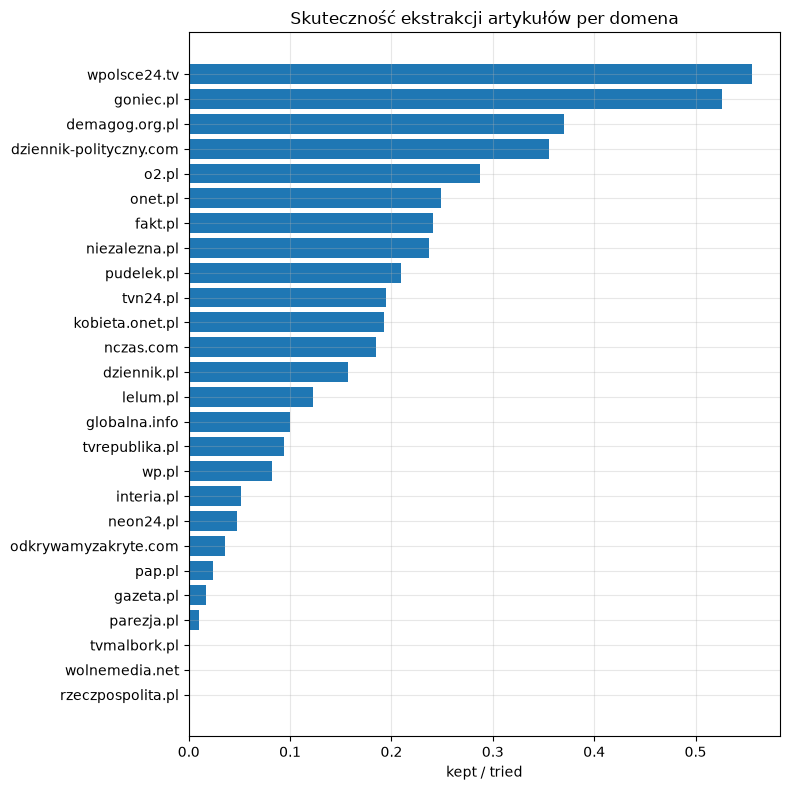

In [41]:
fig, ax = plt.subplots(figsize=(8, 8))
funnel_sorted = funnel.sort_values("kept_ratio", na_position="first")
ax.barh(funnel_sorted.index, funnel_sorted["kept_ratio"].fillna(0))
ax.set_xlabel("kept / tried")
ax.set_title("Skuteczność ekstrakcji artykułów per domena")
plt.tight_layout()
plt.show()

## 4. Podstawowe statystyki artykułów

Łączymy artykuły ze strata/rankiem Tranco i patrzymy na długość tekstu, obecność autora i wykrywanie języka.

In [12]:
articles = articles.merge(
    domains_frame[["domain", "stratum", "rank_tranco"]],
    on="domain",
    how="left",
    suffixes=("", "_frame"),
)
articles["stratum"] = articles["stratum_frame"].fillna(articles["stratum"])
articles = articles.drop(columns=["stratum_frame"])
articles[
    ["domain", "stratum", "rank_tranco", "n_words", "author_present", "languages"]
].describe(include="all")

,domain,stratum,rank_tranco,n_words,author_present,languages
count,1141,1141,774.000000,1141.000000,1141,1141
unique,23,3,NaN,NaN,2,12
top,dziennik-polityczny.com,S1,NaN,NaN,True,pol
freq,60,515,NaN,NaN,1014,980
mean,NaN,NaN,42592.184755,533.439089,NaN,NaN
std,NaN,NaN,80295.035574,484.931043,NaN,NaN
min,NaN,NaN,807.000000,150.000000,NaN,NaN
25%,NaN,NaN,4332.000000,268.000000,NaN,NaN
50%,NaN,NaN,7300.000000,392.000000,NaN,NaN
75%,NaN,NaN,25749.000000,603.000000,NaN,NaN


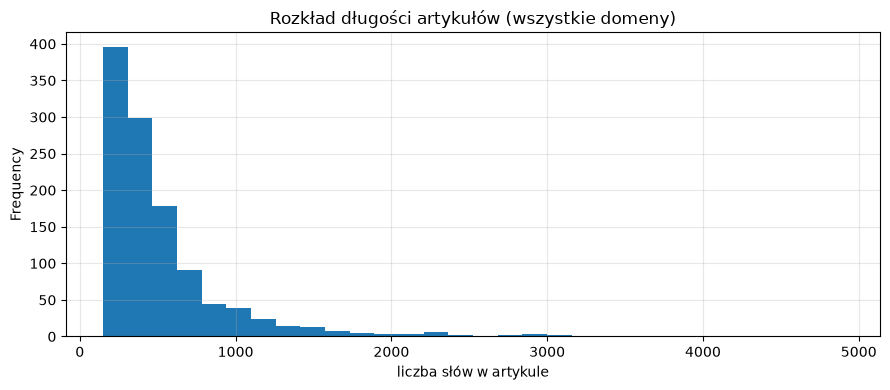

,count,mean,50%,min,max
stratum,,,,,
S1,515.0,462.831068,339.0,150.0,4693.0
S2,259.0,585.583012,430.0,154.0,3330.0
S3,367.0,595.722071,442.0,151.0,4899.0


In [13]:
fig, ax = plt.subplots()
articles["n_words"].plot(kind="hist", bins=30, ax=ax)
ax.set_xlabel("liczba słów w artykule")
ax.set_title("Rozkład długości artykułów (wszystkie domeny)")
plt.tight_layout()
plt.show()

articles.groupby("stratum")["n_words"].describe()[
    ["count", "mean", "50%", "min", "max"]
]

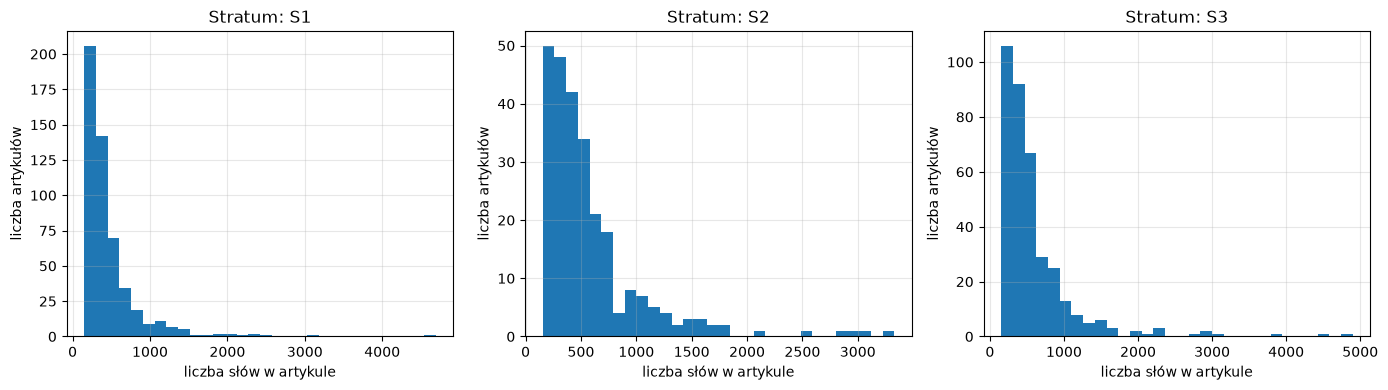

In [52]:
# 3 histograms for n_words each for each stratum:
strata = articles["stratum"].unique()
strata = sorted(strata, key=lambda s: int(s[1:]) if s.startswith("S") else float("inf"))
fig, axes = plt.subplots(1, len(strata), figsize=(14, 4))
for ax, stratum in zip(axes, strata, strict=False):
    articles[articles["stratum"] == stratum]["n_words"].plot(
        kind="hist", bins=30, ax=ax
    )
    ax.set_title(f"Stratum: {stratum}")
    ax.set_xlabel("liczba słów w artykule")
    ax.set_ylabel("liczba artykułów")
plt.tight_layout()
plt.show()

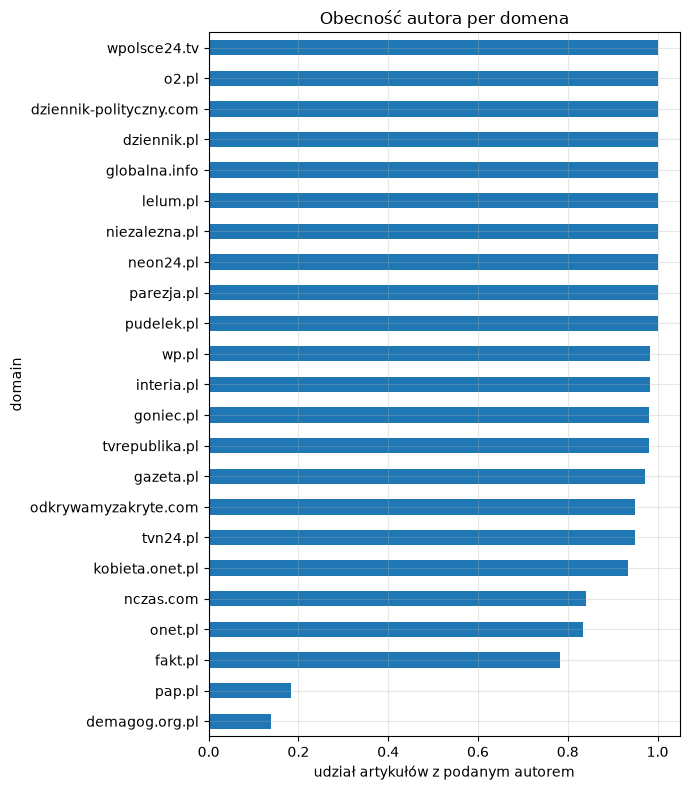

In [14]:
author_rate = articles.groupby("domain")["author_present"].mean().sort_values()
ax = author_rate.plot(kind="barh", figsize=(7, 8))
ax.set_xlabel("udział artykułów z podanym autorem")
ax.set_title("Obecność autora per domena")
plt.tight_layout()
plt.show()

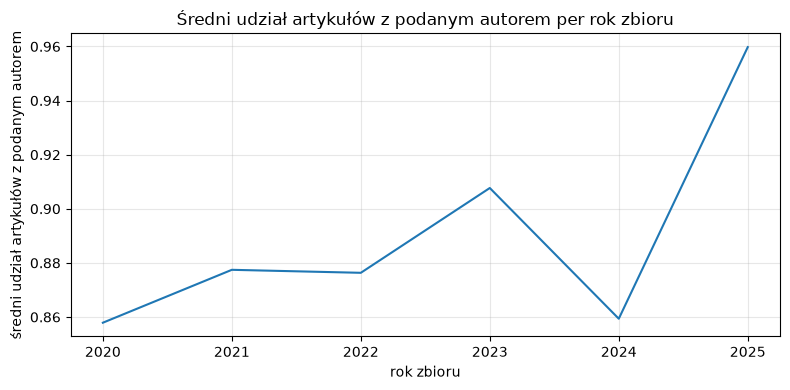

In [32]:
# wykres liczby autorów w czasie (z wszystkich artykułów, nie per domena):
author_counts = articles.groupby("collection_year_dir")["author_present"].mean()
ax = author_counts.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średni udział artykułów z podanym autorem")
ax.set_title("Średni udział artykułów z podanym autorem per rok zbioru")
plt.tight_layout()
plt.show()

In [15]:
lang_counts = articles["languages"].value_counts()
print(lang_counts)
non_pure_pol = articles[articles["languages"] != "pol"]
print(
    f"\nArtykuły z wykrytym więcej niż jednym językiem: {len(non_pure_pol)} / {len(articles)}"
)
non_pure_pol[["domain", "title", "languages"]]

languages
pol            980
pol,eng        146
pol,jpn          4
pol,ita          2
pol,fra          2
pol,ita,eng      1
pol,rus          1
pol,ukr          1
pol,spa          1
pol,jpn,eng      1
pol,lat          1
pol,ind          1
Name: count, dtype: int64

Artykuły z wykrytym więcej niż jednym językiem: 161 / 1141


,domain,title,languages
6,demagog.org.pl,Ilu seniorów mieszka w Warszawie?,"pol,eng"
60,interia.pl,Liga angielska - 14. kolejka League Two: Exete...,"pol,eng"
62,interia.pl,Jest kara dla Milika. Kontrowersje w sprawie s...,"pol,ita"
66,interia.pl,Eric Burdon (The Animals) zakpił z Donalda Tru...,"pol,eng"
80,lelum.pl,Pobierasz zasiłek macierzyński? Ekspert zauważ...,"pol,eng"
...,...,...,...
1057,niezalezna.pl,Producent bananów zwalnia pracowników za... st...,"pol,eng"
1058,niezalezna.pl,Rollercoaster w meczu Igi Świątek z Rosjanką: ...,"pol,eng"
1059,niezalezna.pl,Zwolnienie więźniów na Białorusi. Łukaszenka k...,"pol,eng"
1070,onet.pl,Akcja ratunkowa w Chorwacji. Polak ukarany man...,"pol,eng"


## 5. Rozkład w czasie: `pub_date` vs `crawl_id`

Artykuły pochodzą z Common Crawl, który indeksuje strony z pewnym opóźnieniem względem publikacji — sprawdzamy,
czy `pub_date` faktycznie odpowiada deklarowanemu rokowi folderu i jak duży jest ten lag.

In [16]:
articles["pub_date"] = pd.to_datetime(articles["pub_date"], errors="coerce")
articles["pub_year_check"] = articles["pub_date"].dt.year

mismatch = articles[
    articles["pub_year_check"].astype("Int64")
    != articles["collection_year_dir"].astype(int)
]
print(
    f"Artykuły, dla których pub_date nie zgadza się z folderem roku: {len(mismatch)} / {len(articles)}"
)
mismatch[["domain", "collection_year_dir", "pub_date", "crawl_id"]]

Artykuły, dla których pub_date nie zgadza się z folderem roku: 0 / 1141


,domain,collection_year_dir,pub_date,crawl_id


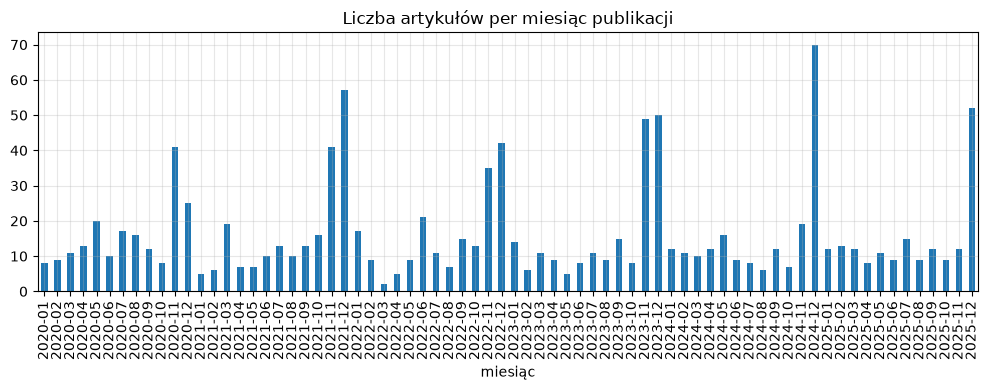

In [17]:
ax = (
    articles["pub_date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
    .plot(kind="bar", figsize=(10, 4))
)
ax.set_title("Liczba artykułów per miesiąc publikacji")
ax.set_xlabel("miesiąc")
plt.tight_layout()
plt.show()

## 6. Duplikaty i jakość tekstu

Sprawdzamy duplikaty treści (`text_sha1`) i krótkie artykuły

In [18]:
dup_counts = articles["text_sha1"].value_counts()
dups = dup_counts[dup_counts > 1]
print(f"Zduplikowanych treści (ten sam text_sha1 w >1 artykule): {len(dups)}")
articles[articles["text_sha1"].isin(dups.index)][
    ["domain", "collection_year_dir", "title", "text_sha1"]
].sort_values("text_sha1")

Zduplikowanych treści (ten sam text_sha1 w >1 artykule): 7


,domain,collection_year_dir,title,text_sha1
655,kobieta.onet.pl,2023,Jak zmniejszyć rachunki za pranie? Wystarczy z...,054e3e7de145c35817d4d714738dee3bd80aa330
847,kobieta.onet.pl,2024,Jak zmniejszyć rachunki za pranie? Wystarczy z...,054e3e7de145c35817d4d714738dee3bd80aa330
652,kobieta.onet.pl,2023,"Garnki tak trwałe, że przekażesz je wnukom. Te...",5e33fd9df26fc7bd630a8cbcf3cc60b70ded5b64
720,onet.pl,2023,"Garnki tak trwałe, że przekażesz je wnukom. Te...",5e33fd9df26fc7bd630a8cbcf3cc60b70ded5b64
846,kobieta.onet.pl,2024,Zagadka na spostrzegawczość. Znajdź na obrazku...,6d3354142bb217cf04d54881bc206cd657666dd5
901,onet.pl,2024,Zagadka na spostrzegawczość. Znajdź na obrazku...,6d3354142bb217cf04d54881bc206cd657666dd5
465,kobieta.onet.pl,2022,"Sinead O'Connor wyjawiła, w jaki sposób jej sy...",9799b0940e2b6c0ef3d60f38a37804a6954e71c5
525,onet.pl,2022,"Sinead O'Connor wyjawiła, w jaki sposób jej sy...",9799b0940e2b6c0ef3d60f38a37804a6954e71c5
70,kobieta.onet.pl,2020,Pandora wyprodukowała specjalne charmsy z okaz...,afaa92589d7e236dc568ee888b4c178019d76744
135,onet.pl,2020,Pandora wyprodukowała specjalne charmsy z okaz...,afaa92589d7e236dc568ee888b4c178019d76744


In [19]:
short_articles = articles.sort_values("n_words").head(10)
short_articles[["domain", "collection_year_dir", "title", "n_words"]]

,domain,collection_year_dir,title,n_words
161,pudelek.pl,2020,"Łukasz Darłak zagra w ""Na Wspólnej"". ""Cześć ws...",150
16,dziennik-polityczny.com,2020,Oszustwo na żołnierza. 63-latka z Suwałk strac...,151
387,wp.pl,2021,"Finalista US Open został ojcem. ""Zrozumiałem, ...",153
931,tvn24.pl,2024,Potrącenie na przejściu dla pieszych. Nie żyje...,154
656,kobieta.onet.pl,2023,"Intruz zabrał mikrofon Grecie Thunberg. ""Przys...",154
99,nczas.com,2020,Koniec z niszczeniem pomników w USA. Trump pow...,154
876,niezalezna.pl,2024,Nie lubię poniedziałku! Zobacz najlepsze MEMY ...,154
694,niezalezna.pl,2023,Razem przeciw Rosji | Niezalezna.pl,155
1025,kobieta.onet.pl,2025,"Ośmiolatek zadzwonił na policję. ""Mimo silnych...",155
1057,niezalezna.pl,2025,Producent bananów zwalnia pracowników za... st...,155


## 7. Wstępne sygnały stylometryczne (eksploracyjne, pod kątem AI)

Cechy:
- średnia długość zdania i słowa,
- bogactwo słownictwa (type-token ratio),
- liczba akapitów (`\n\n`),
- częstość wybranych fraz/znaków częściej kojarzonych z tekstem generowanym przez LLM po polsku
  (myślnik `—`, "podsumowując", "warto zauważyć", "należy zauważyć", "ponadto", "jednakże").

In [20]:
AI_MARKER_PATTERNS = {
    "em_dash": "—",
    "podsumowujac": r"podsumowuj\w*",
    "warto_zauwazyc": r"warto zauwa\w+",
    "nalezy_zauwazyc": r"nale\u017cy zauwa\w+",
    "ponadto": r"\bponadto\b",
    "jednakze": r"\bjednak\u017ce\b",
}


def text_stats(text: str) -> dict:
    words = re.findall(
        r"\b[\w\u0105\u0107\u0119\u0142\u0144\u00f3\u015b\u017a\u017c]+\b", text.lower()
    )
    sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    n_words = max(len(words), 1)
    stats = {
        "avg_sentence_len_words": n_words / max(len(sentences), 1),
        "avg_word_len_chars": sum(len(w) for w in words) / n_words,
        "ttr": len(set(words)) / n_words,
        "n_paragraphs": text.count("\n\n") + 1,
    }
    for name, pattern in AI_MARKER_PATTERNS.items():
        stats[f"marker_{name}_per_1000w"] = (
            1000 * len(re.findall(pattern, text, flags=re.IGNORECASE)) / n_words
        )
    return stats


style_df = pd.DataFrame(
    articles["text"].apply(text_stats).tolist(), index=articles.index
)
articles_style = pd.concat(
    [articles[["domain", "stratum", "collection_year_dir"]], style_df], axis=1
)
articles_style.groupby("domain").mean(numeric_only=True).round(3)

,avg_sentence_len_words,avg_word_len_chars,ttr,n_paragraphs,marker_em_dash_per_1000w,marker_podsumowujac_per_1000w,marker_warto_zauwazyc_per_1000w,marker_nalezy_zauwazyc_per_1000w,marker_ponadto_per_1000w,marker_jednakze_per_1000w
domain,,,,,,,,,,
demagog.org.pl,14.164,5.944,0.517,1.0,0.484,0.088,0.030,0.000,0.180,0.091
dziennik-polityczny.com,14.093,5.996,0.647,1.0,1.436,0.099,0.024,0.032,0.107,0.047
dziennik.pl,14.534,5.733,0.682,1.0,0.126,0.065,0.000,0.000,0.156,0.000
fakt.pl,10.261,5.715,0.612,1.0,3.699,0.013,0.000,0.000,0.068,0.000
gazeta.pl,12.878,5.745,0.660,1.0,0.000,0.057,0.000,0.000,0.006,0.000
globalna.info,16.145,5.957,0.610,1.0,0.609,0.018,0.000,0.000,0.055,0.104
goniec.pl,13.352,5.865,0.651,1.0,0.285,0.048,0.000,0.000,0.055,0.030
interia.pl,13.223,5.720,0.670,1.0,0.000,0.000,0.000,0.000,0.208,0.033
kobieta.onet.pl,13.424,5.743,0.650,1.0,5.586,0.053,0.000,0.000,0.281,0.000


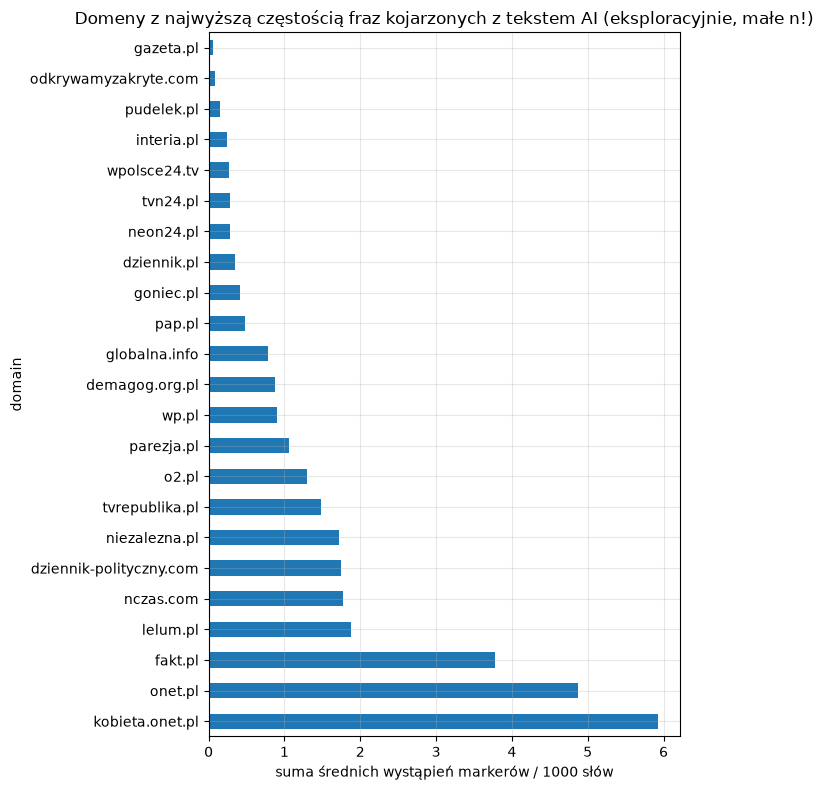

In [21]:
marker_cols = [c for c in articles_style.columns if c.startswith("marker_")]
marker_totals = (
    articles_style.groupby("domain")[marker_cols]
    .mean()
    .sum(axis=1)
    .sort_values(ascending=False)
)

ax = marker_totals.plot(kind="barh", figsize=(7, 8))
ax.set_xlabel("suma średnich wystąpień markerów / 1000 słów")
ax.set_title(
    "Domeny z najwyższą częstością fraz kojarzonych z tekstem AI (eksploracyjnie, małe n!)"
)
plt.tight_layout()
plt.show()

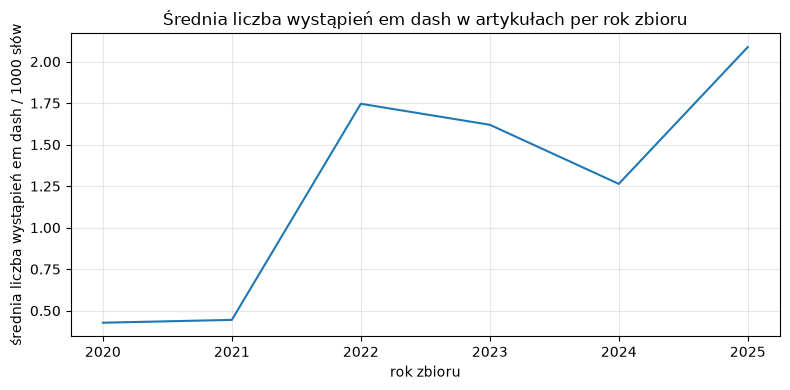

In [33]:
# em dash count in time (from all the articles, not per domain) as a plot:
em_dash_counts = articles_style.groupby("collection_year_dir")[
    "marker_em_dash_per_1000w"
].mean()
ax = em_dash_counts.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średnia liczba wystąpień em dash / 1000 słów")
ax.set_title("Średnia liczba wystąpień em dash w artykułach per rok zbioru")
plt.tight_layout()
plt.show()

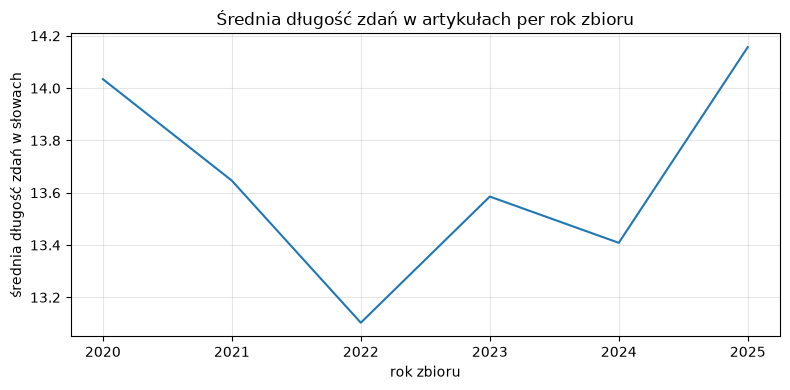

In [34]:
# wykres ze średnią długością zdań w czasie (z wszystkich artykułów, nie per domena):
avg_sentence_len = articles_style.groupby("collection_year_dir")[
    "avg_sentence_len_words"
].mean()
ax = avg_sentence_len.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średnia długość zdań w słowach")
ax.set_title("Średnia długość zdań w artykułach per rok zbioru")
plt.tight_layout()
plt.show()

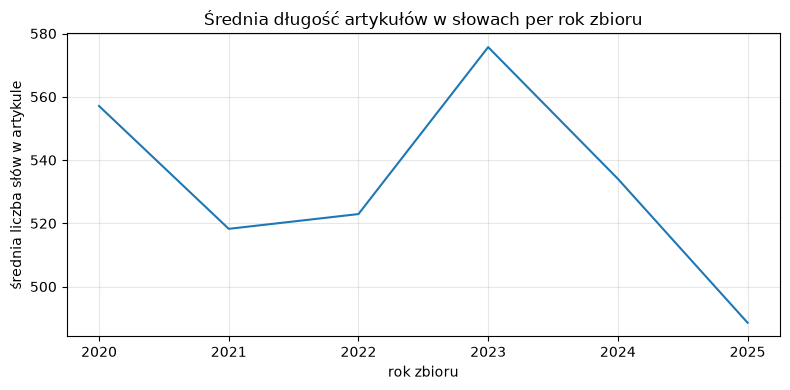

In [35]:
# wykres ze średnią dgością artykułów w czasie (z wszystkich artykułów, nie per domena):
avg_n_words = articles.groupby("collection_year_dir")["n_words"].mean()
ax = avg_n_words.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średnia liczba słów w artykule")
ax.set_title("Średnia długość artykułów w słowach per rok zbioru")
plt.tight_layout()
plt.show()

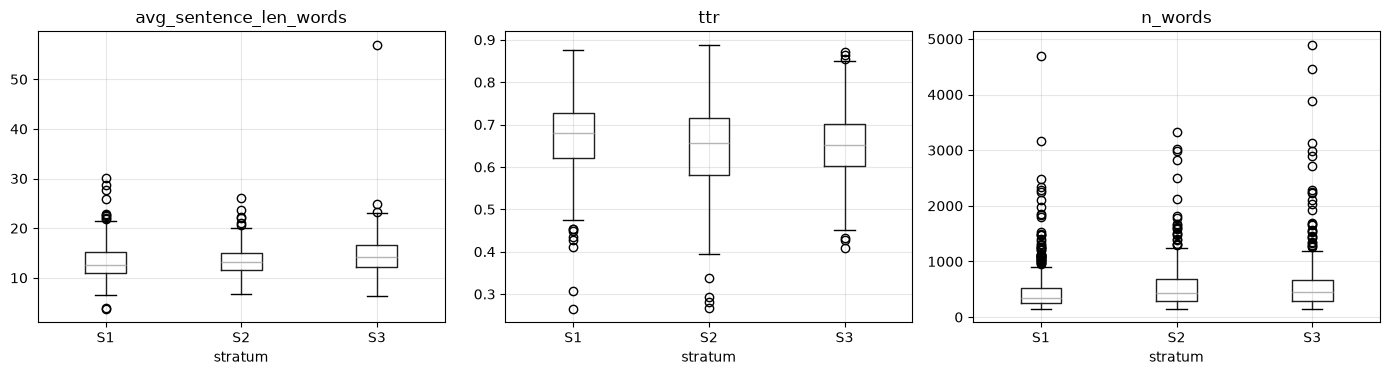

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["avg_sentence_len_words", "ttr", "n_words"], strict=False):
    if ax == axes[2]:
        articles.boxplot(column="n_words", by="stratum", ax=ax)
        ax.set_title("n_words")
        ax.set_xlabel("stratum")
    else:
        articles_style.boxplot(column=col, by="stratum", ax=ax)
        ax.set_title(col)
        ax.set_xlabel("stratum")
plt.suptitle("")
plt.tight_layout()
plt.show()